### 实验3 卷积神经网络计算机视觉基础 (2 CIFAR-10)

#### 一、基本实现过程
##### 1.1 基本设置
（1）导入torch等第三方库


In [1]:
import random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F # 函数式接口模块
from torch.utils.data import DataLoader, Subset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

import json
import time
from pathlib import Path
# 将训练历史、验证结果和测试比较表按表格格式显示。
from IPython.display import display
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 所有结果放在当前实验目录下，重复运行时覆盖同名结果。
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
torch.set_num_threads(4) # 限制CPU线程数，避免共享环境中占用过多线程


（2）设置图表显示

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

（3）观察设备情况，以便后面使用GPU

In [ ]:
# 优先选用GPU，训练和测试阶段都使用这一设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


（4）设置固定随机种子，以便复现

In [4]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

##### 1.2 数据导入与预处理
（1）导入数据集并观察形状

In [5]:
# 读取已经准备好的CIFAR-10本地数据。
import tarfile

tar_path = './data/cifar-10-batches-py.tar.gz'
if not Path('data/cifar-10-batches-py').is_dir():
    with tarfile.open(tar_path, 'r:gz') as tar:
        tar.extractall('./data', filter='data')

In [6]:
# 统一图像变换，固定训练／验证划分，并按batch组织数据。
from torchvision import datasets, transforms

# 训练、验证、测试使用相同的预处理。
transform = transforms.Compose([
    transforms.ToTensor(), # 将H×W×C图像转为C×H×W浮点张量，像素缩放到[0, 1]
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # 三通道统一缩放至[-1, 1]
])

full_train_dataset = datasets.CIFAR10(
    root='./data', train=True, transform=transform, download=False
)
test_dataset = datasets.CIFAR10(
    root='./data', train=False, transform=transform, download=False
)

# 从原训练集中分层抽取 20% 为固定验证集；只划分一次。
val_ratio = 0.2
train_indices, val_indices = train_test_split(
    np.arange(len(full_train_dataset)), test_size=val_ratio,
    random_state=42, stratify=full_train_dataset.targets
)
# Subset只保存划分索引，训练和验证数据不会重叠。
train_dataset = Subset(full_train_dataset, train_indices.tolist())
val_dataset = Subset(full_train_dataset, val_indices.tolist())

# 多进程完成原有图像变换，CPU 张量按 batch 传入 GPU。
loader_options = {'num_workers': 2, 'persistent_workers': True,
                  'pin_memory': device.type == 'cuda'}
g = torch.Generator().manual_seed(42)
# 训练时打乱样本；计算训练、验证和测试指标时保持固定顺序。
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=g, **loader_options)
train_eval_loader = DataLoader(train_dataset, batch_size=64, shuffle=False, **loader_options)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, **loader_options)


In [7]:
# 检查三个数据子集的样本数和单张RGB图像的通道、尺寸。
print(f"训练集样本数: {len(train_dataset)}")
print(f"验证集样本数: {len(val_dataset)}")
print(f"测试集样本数: {len(test_dataset)}")
print(f"单张图片形状: {tuple(train_dataset[0][0].shape)}")

训练集样本数: 40000
验证集样本数: 10000
测试集样本数: 10000
单张图片形状: (3, 32, 32)


##### 1.3 基础网络结构定义与模型训练
（1）基础结构：Conv(3→32)→Pool→Conv(32→64)→Pool→Flatten→Linear(4096→128→10)。
两次2×2池化将32×32缩小到8×8；所有卷积均为3×3、padding=1，激活为ReLU。


In [8]:
# 定义基础CNN，两次池化后将32×32图像特征缩小为8×8。
# 自定义CNN结构
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # 第一层卷积：3个输入通道，32个输出通道
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # 第二层卷积：32个输入通道，64个输出通道
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # 最大池化：尺寸缩小一半
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 全连接层
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # 第一组卷积 + 激活 + 池化
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)
        
        # 第二组卷积 + 激活 + 池化
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        # 展平
        x = torch.flatten(x, start_dim=1)

        # 全连接分类
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


（2）创建model对象，设置loss函数与优化器

In [9]:
# 为基础CNN创建交叉熵损失和Adam优化器。
model = CNN().to(device) # 基础模型
criterion = nn.CrossEntropyLoss() # 交叉熵损失
optimizer = optim.Adam(model.parameters(), lr=0.001) # 延续原代码的优化器


（3）训练并记录每轮训练集和固定验证集指标，按验证集选择最佳权重。
所有结构均训练15轮，每轮结束后在eval模式下完整评估训练集和验证集。验证Acc更高时保存权重，相同则选验证Loss更低的轮次。


In [10]:
# 训练各候选CNN，记录每轮指标，并恢复最佳验证轮次。
def train_model(model, epochs, batch, optimizer, run_name):
    model = model.to(device)
    # 每个模型重新设置相同的 batch 顺序，保证结构对比的条件一致。
    train_loader.generator = torch.Generator().manual_seed(42)
    # 采样器另有随机数生成器，需要一并重置才能统一各模型的batch顺序。
    train_loader.sampler.generator = torch.Generator().manual_seed(42)
    # 记录每轮结果，并初始化最佳验证指标。
    loss_result = []
    best_acc, best_loss, best_epoch = -1.0, float('inf'), 0
    checkpoint = OUTPUT_DIR / f'{run_name}_best.pt'
    # GPU运算是异步的，同步后再开始计时。
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train() # 切换为训练模式，允许参数通过梯度更新
        for batch_x, batch_y in train_loader:
            # 图像与标签必须和模型位于同一设备。
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad() # 清空上一批次残留的梯度
            preds_y = model(batch_x) # 前向传播，输出各类别的logits
            loss_train = criterion(preds_y, batch_y)
            loss_train.backward() # 反向传播，计算各参数的梯度
            optimizer.step() # 根据梯度更新当前模型的参数

        # 同一个 epoch 结束后，在 eval 模式下计算训练集和验证集指标。
        epoch_result = {'Epoch': epoch + 1}
        model.eval()
        with torch.no_grad():
            for split, loader in [('Train', train_eval_loader), ('Val', val_loader)]:
                total_loss_sum, correct, sample_num = 0.0, 0, 0
                for batch_x, batch_y in loader:
                    batch_x = batch_x.to(device)
                    batch_y = batch_y.to(device)
                    preds_y = model(batch_x)
                    loss = criterion(preds_y, batch_y)
                    # 按批次样本数加权，避免最后一个小batch影响平均Loss。
                    total_loss_sum += loss.item() * batch_y.size(0)
                    correct += (preds_y.argmax(dim=1) == batch_y).sum().item()
                    sample_num += batch_y.size(0)
                epoch_result[f'{split}_Loss'] = total_loss_sum / sample_num
                epoch_result[f'{split}_Acc'] = correct / sample_num

        # 仅依据验证集选权重；准确率相同时，选择验证 Loss 较小的轮次。
        val_acc, val_loss = epoch_result['Val_Acc'], epoch_result['Val_Loss']
        if val_acc > best_acc or (val_acc == best_acc and val_loss < best_loss):
            best_acc, best_loss, best_epoch = val_acc, val_loss, epoch + 1
            torch.save(model.state_dict(), checkpoint)

        loss_result.append(epoch_result)
        print(
            f"{run_name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {epoch_result['Train_Loss']:.4f}, "
            f"Train Acc: {epoch_result['Train_Acc']:.2%} | "
            f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2%}", flush=True
        )

    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    # 训练结束后恢复最佳验证轮次，后面的测试及保存均使用这组权重。
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    model.eval()
    # 保存比较表需要的最佳轮次与耗时，并把完整历史写入CSV。
    model.best_epoch = best_epoch
    model.training_seconds = seconds
    history = pd.DataFrame(loss_result)
    history.to_csv(OUTPUT_DIR / f'{run_name}_history.csv', index=False)
    print(f'{run_name}: 最佳轮次 {best_epoch}，验证 Acc {best_acc:.2%}，耗时 {seconds:.1f}s')
    return history


In [11]:
# 按统一超参数训练基础模型，保存结构对比所需的记录。
train_result_df = train_model(model, epochs=15, batch=64, optimizer=optimizer, run_name='CNN')
display(train_result_df.style.format({
    'Train_Loss': '{:.4f}', 'Train_Acc': '{:.2%}',
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}'
}).hide(axis='index'))
models = {'CNN': model}
results_dict = {'CNN': train_result_df}


CNN | Epoch 1/15 | Train Loss: 1.0930, Train Acc: 61.35% | Val Loss: 1.1411, Val Acc: 59.89%


CNN | Epoch 2/15 | Train Loss: 0.8934, Train Acc: 68.51% | Val Loss: 0.9959, Val Acc: 64.61%


CNN | Epoch 3/15 | Train Loss: 0.7716, Train Acc: 72.97% | Val Loss: 0.9279, Val Acc: 67.63%


CNN | Epoch 4/15 | Train Loss: 0.6509, Train Acc: 77.15% | Val Loss: 0.8998, Val Acc: 68.48%


CNN | Epoch 5/15 | Train Loss: 0.5194, Train Acc: 82.22% | Val Loss: 0.8716, Val Acc: 70.28%


CNN | Epoch 6/15 | Train Loss: 0.4569, Train Acc: 84.42% | Val Loss: 0.9060, Val Acc: 70.41%


... (7 outputs left out)

CNN | Epoch 14/15 | Train Loss: 0.0853, Train Acc: 97.10% | Val Loss: 1.6550, Val Acc: 69.74%


CNN | Epoch 15/15 | Train Loss: 0.1164, Train Acc: 95.79% | Val Loss: 1.8476, Val Acc: 68.41%


CNN: 最佳轮次 6，验证 Acc 70.41%，耗时 32.5s


Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc
1,1.0930,61.35%,1.1411,59.89%
2,0.8934,68.51%,0.9959,64.61%
3,0.7716,72.97%,0.9279,67.63%
4,0.6509,77.15%,0.8998,68.48%
5,0.5194,82.22%,0.8716,70.28%
6,0.4569,84.42%,0.9060,70.41%
7,0.4393,84.21%,0.9868,68.77%
8,0.3151,89.58%,0.9836,69.50%
9,0.2158,93.23%,1.0583,70.21%
10,0.1623,95.05%,1.1583,70.11%


（4）绘制 Baseline 的训练集、验证集 Loss 与 Acc 曲线，查看收敛和泛化情况

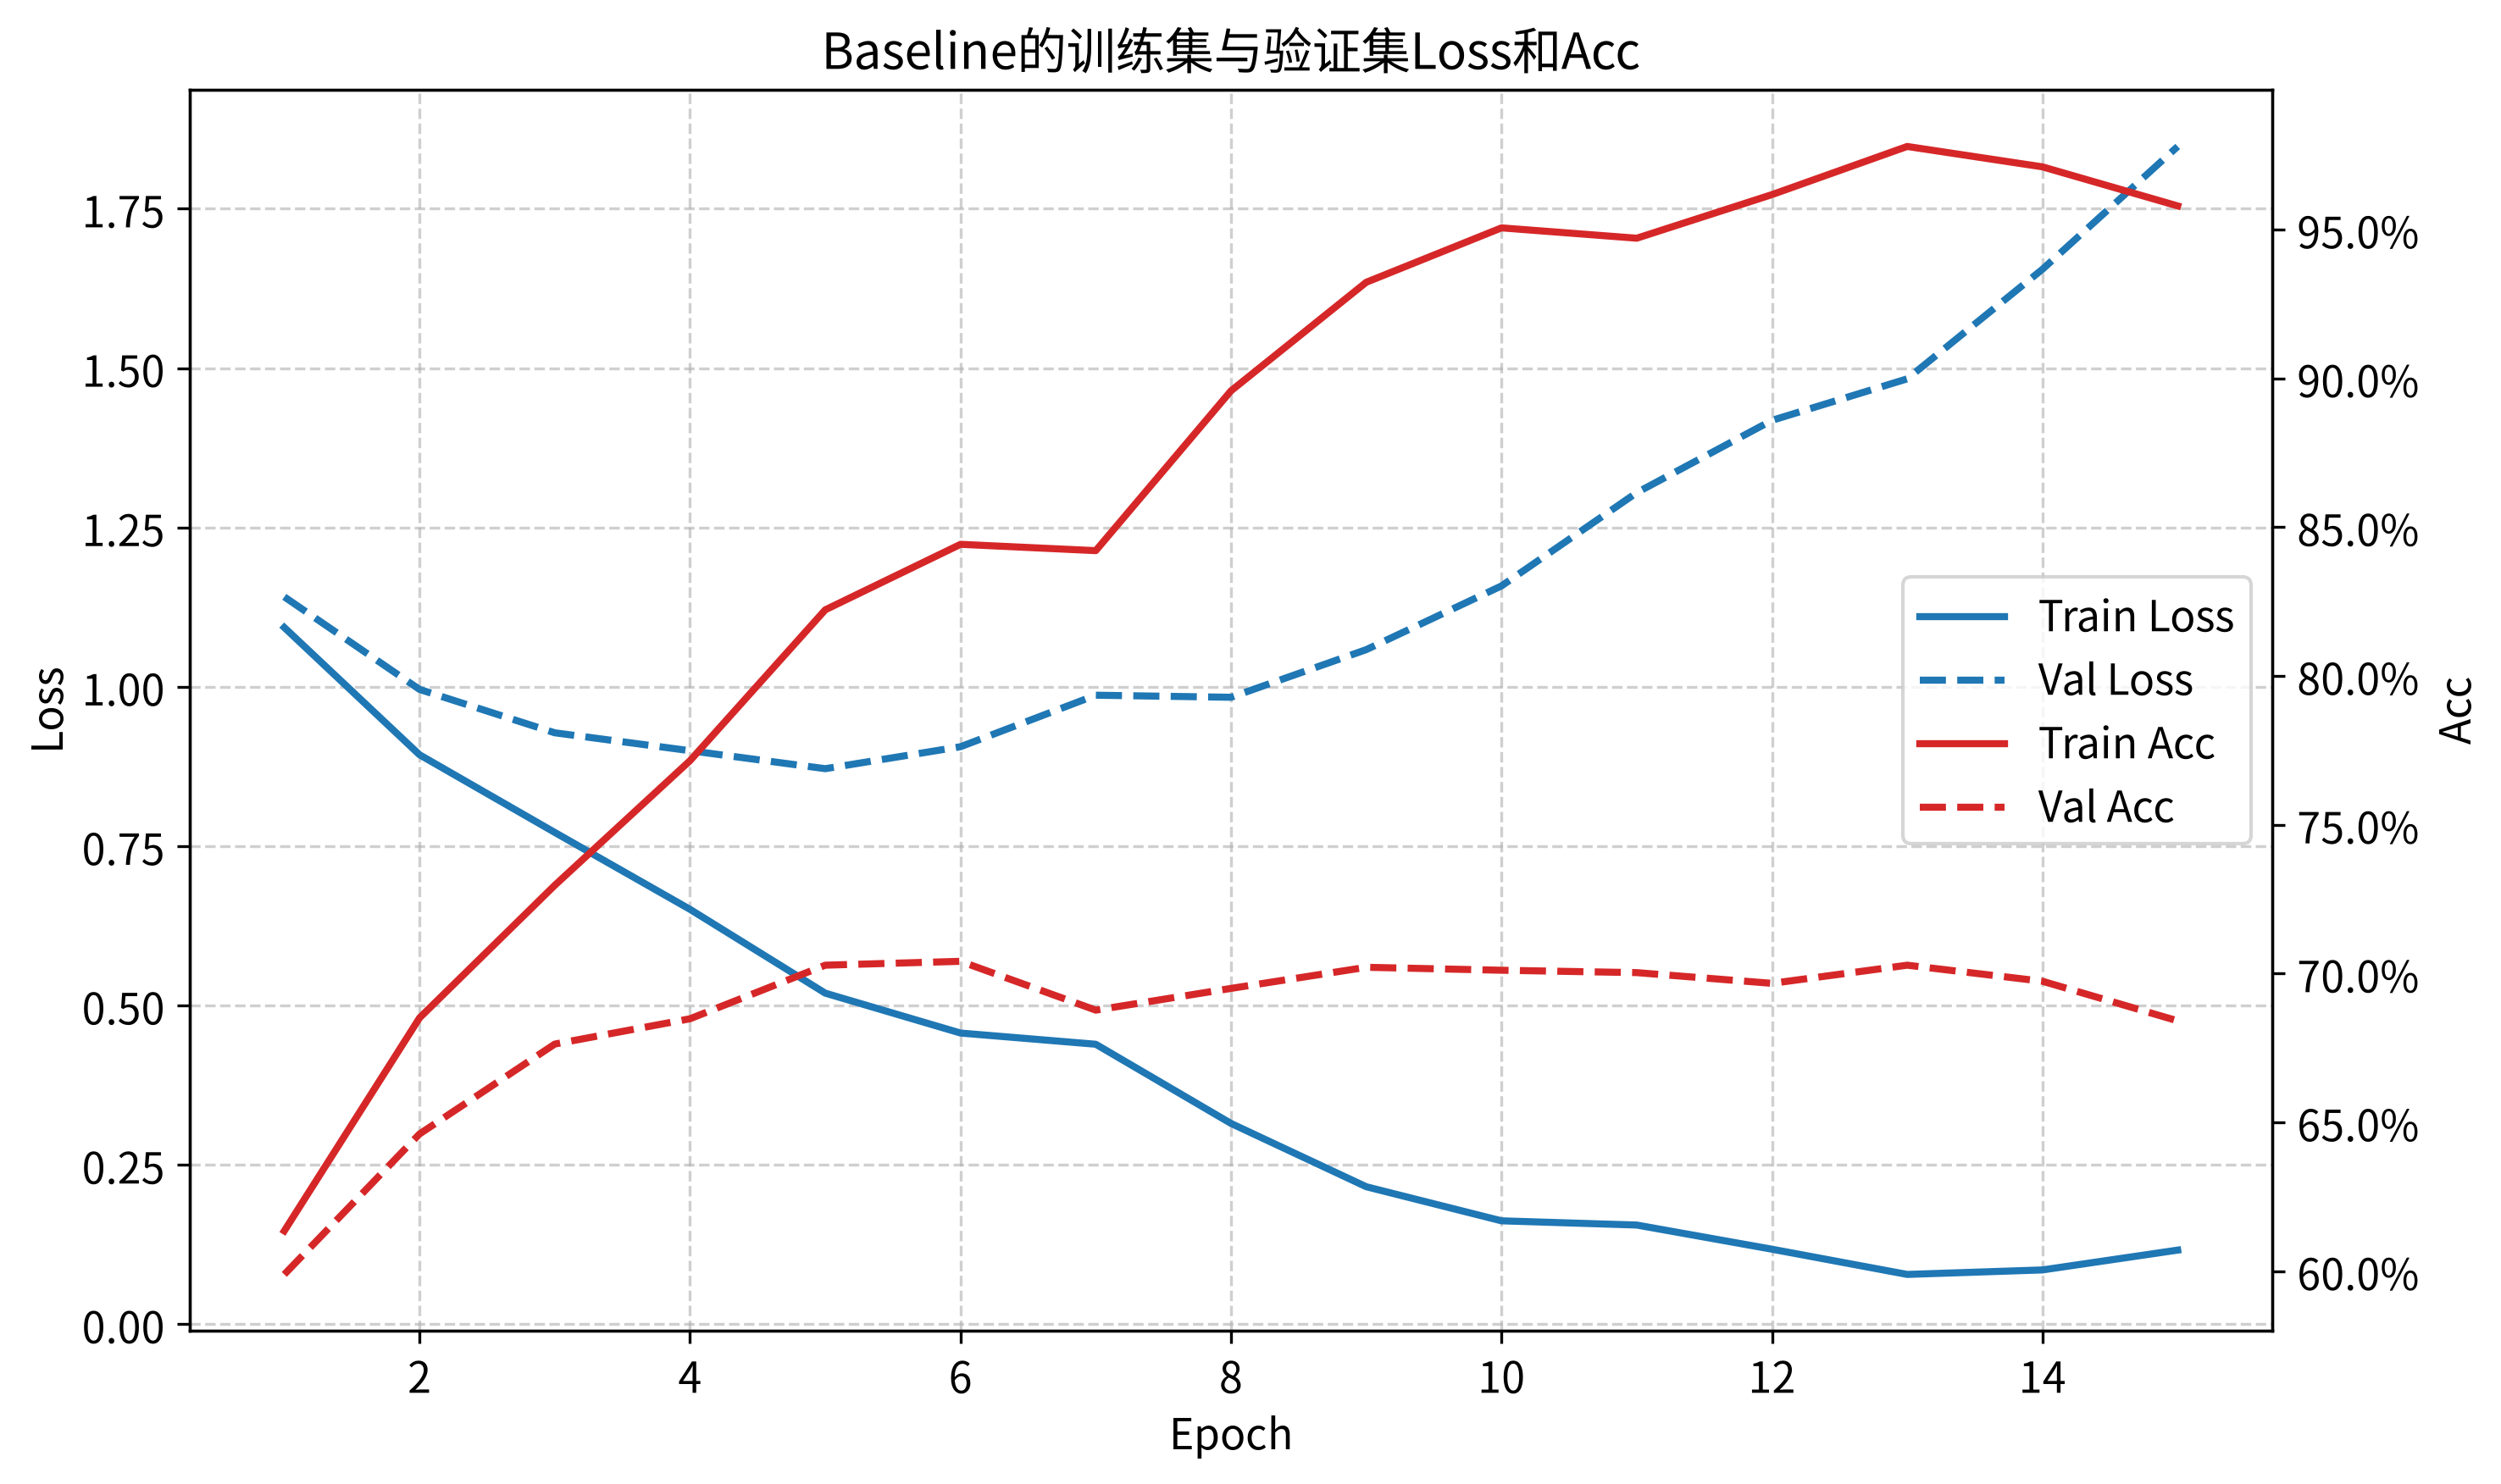

In [12]:
# 同时绘制基础模型的训练和验证指标，检查是否开始过拟合。
# 分别绘制训练集、验证集的 Loss 与 Acc（实线：训练；虚线：验证）。
epochs = range(1, len(train_result_df) + 1)
fig, ax1 = plt.subplots(figsize=(10, 6))

line1 = ax1.plot(epochs, train_result_df['Train_Loss'],
                 label='Train Loss', color='tab:blue', linewidth=2)
line2 = ax1.plot(epochs, train_result_df['Val_Loss'],
                 label='Val Loss', color='tab:blue', linestyle='--', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
line3 = ax2.plot(epochs, train_result_df['Train_Acc'],
                 label='Train Acc', color='tab:red', linewidth=2)
line4 = ax2.plot(epochs, train_result_df['Val_Acc'],
                 label='Val Acc', color='tab:red', linestyle='--', linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))

lines = line1 + line2 + line3 + line4
ax1.legend(lines, [line.get_label() for line in lines], loc='center right', fontsize=12)
plt.title('Baseline的训练集与验证集Loss和Acc', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'baseline_curves.png', bbox_inches='tight')
plt.show()


#### 二、基础CNN的结构对照与进一步调整
##### 2.1 原有三种结构

| 名称 | 卷积结构 | 展平后维度 | 全连接分类器 |
| :--- | :--- | :--- | :--- |
| CNN | Conv32→Pool→Conv64→Pool | 64×8×8 | 128→10 |
| CNN3 | Conv32→Pool→Conv64→Pool→Conv128→Pool | 128×4×4 | 128→10 |
| CNNDouble | Conv32→Conv32→Pool→Conv64→Conv64→Pool | 64×8×8 | 128→10 |

先保留基础模型及前次的两种改动作为对照，再进一步增加卷积深度、比较通道宽度，并检查归一化层和Dropout的作用。


In [13]:
# 在基础CNN上定义两种扩展结构，并分别独立初始化和训练。
# 方案一：在第二次池化后、全连接分类器前增加第三个卷积块。
class CNN3(CNN):
    def __init__(self):
        super(CNN3, self).__init__()
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128 * 4 * 4, 128) # 第三次池化后为128×4×4

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        # 额外卷积块组合高层特征，再把空间尺寸从8×8缩小为4×4。
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# 方案二：每次池化前增加一层同通道卷积，池化位置保持不变。
class CNNDouble(CNN):
    def __init__(self):
        super(CNNDouble, self).__init__()
        # 新增卷积保持通道数和空间尺寸，继续复用基础模型的分类器。
        self.conv1_extra = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.conv2_extra = nn.Conv2d(64, 64, kernel_size=3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        # 在池化降采样前增加一次局部特征提取。
        x = self.pool(F.relu(self.conv1_extra(x)))
        x = F.relu(self.conv2(x))
        x = self.pool(F.relu(self.conv2_extra(x)))
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

model_classes = {'CNN': CNN, 'CNN3': CNN3, 'CNNDouble': CNNDouble}
# 每种结构独立初始化并创建优化器，避免沿用其他模型的参数状态。
for name in ['CNN3', 'CNNDouble']:
    set_seed(42)
    current_model = model_classes[name]().to(device)
    current_optimizer = optim.Adam(current_model.parameters(), lr=0.001)
    result = train_model(current_model, epochs=15, batch=64,
                         optimizer=current_optimizer, run_name=name)
    # 保存各自恢复最佳权重后的模型与历史，用于后续统一评估。
    models[name] = current_model
    results_dict[name] = result
    display(result.style.format({
        'Train_Loss': '{:.4f}', 'Train_Acc': '{:.2%}',
        'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}'
    }).hide(axis='index'))


CNN3 | Epoch 1/15 | Train Loss: 1.1327, Train Acc: 59.69% | Val Loss: 1.1609, Val Acc: 58.47%


CNN3 | Epoch 2/15 | Train Loss: 0.9004, Train Acc: 68.58% | Val Loss: 0.9812, Val Acc: 65.31%


CNN3 | Epoch 3/15 | Train Loss: 0.7703, Train Acc: 72.88% | Val Loss: 0.8958, Val Acc: 68.58%


CNN3 | Epoch 4/15 | Train Loss: 0.6473, Train Acc: 77.26% | Val Loss: 0.8384, Val Acc: 70.83%


CNN3 | Epoch 5/15 | Train Loss: 0.5381, Train Acc: 81.51% | Val Loss: 0.8048, Val Acc: 72.40%


CNN3 | Epoch 6/15 | Train Loss: 0.4548, Train Acc: 84.86% | Val Loss: 0.7774, Val Acc: 73.95%


... (24 outputs left out)

CNNDouble | Epoch 14/15 | Train Loss: 0.0773, Train Acc: 97.42% | Val Loss: 1.5318, Val Acc: 72.86%


CNNDouble | Epoch 15/15 | Train Loss: 0.0556, Train Acc: 98.08% | Val Loss: 1.6986, Val Acc: 73.03%


CNNDouble: 最佳轮次 6，验证 Acc 74.32%，耗时 31.9s


Epoch,Train_Loss,Train_Acc,Val_Loss,Val_Acc
1,1.1067,60.26%,1.1497,58.88%
2,0.8847,68.79%,0.9769,66.12%
3,0.6767,76.61%,0.8287,71.31%
4,0.5671,80.20%,0.8036,72.08%
5,0.4733,83.74%,0.7890,73.25%
6,0.3584,88.22%,0.7663,74.32%
7,0.2864,90.21%,0.8391,74.11%
8,0.2219,92.38%,0.9529,73.16%
9,0.1562,94.84%,1.0127,73.45%
10,0.1278,95.81%,1.1040,73.06%


（2）比较所有模型训练／验证 Loss 与 Acc，观察收敛速度和过拟合。


In [14]:
# 在相同坐标下绘制所有结构的Loss与Acc，比较收敛和泛化。
# 不同模型的训练、验证结果对比可视化，后续实验可复用。
def plot_multiple_models_train_result(results_dict, title, filename='comparison_curves.png'):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    # 颜色区分模型，实线和虚线分别表示训练集与验证集。
    for i, (model_name, df) in enumerate(results_dict.items()):
        color = colors[i % len(colors)]
        epochs = range(1, len(df) + 1)
        for split, linestyle in [('Train', '-'), ('Val', '--')]:
            label = f'{model_name} ({split})'
            ax1.plot(epochs, df[f'{split}_Loss'], label=label,
                     color=color, linestyle=linestyle, linewidth=2)
            ax2.plot(epochs, df[f'{split}_Acc'], label=label,
                     color=color, linestyle=linestyle, linewidth=2)

    for ax, metric in [(ax1, 'Loss'), (ax2, 'Acc')]:
        ax.set_title(f'训练集与验证集 {metric}', fontsize=14)
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric, fontsize=12)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(fontsize=12)

    # 将准确率坐标格式化为百分数，并保存对比曲线。
    ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, bbox_inches='tight')
    plt.show()


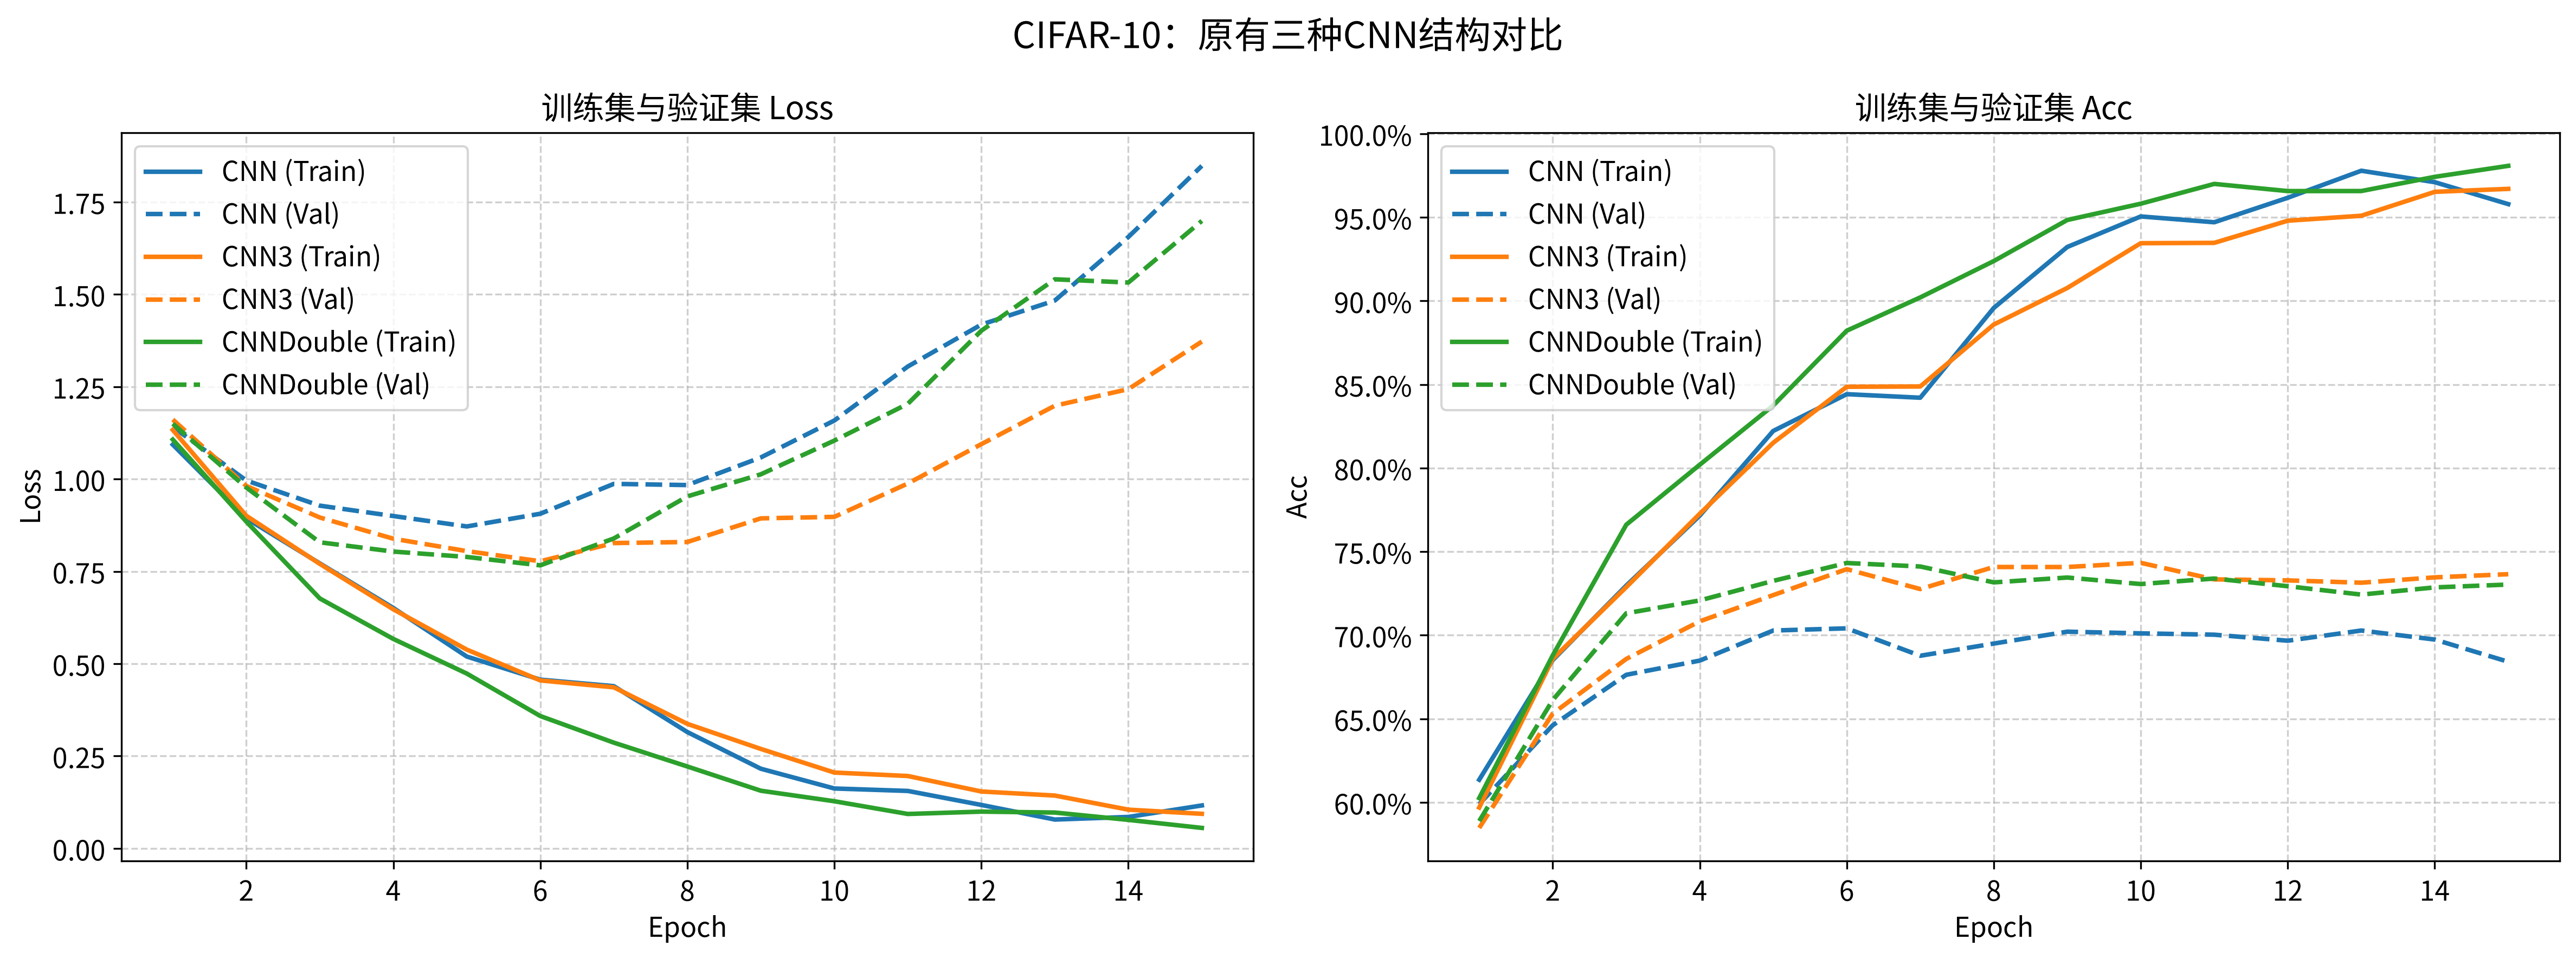

In [15]:
# 先保存原有三种结构的曲线，作为进一步调整前的对照。
plot_multiple_models_train_result(results_dict, 'CIFAR-10：原有三种CNN结构对比',
                                  filename='initial_comparison_curves.png')


##### 2.2 增加卷积深度、通道宽度及CNN内部的正则化层

新增结构均为顺序CNN，每个块由若干个3×3卷积和ReLU组成，块末尾做一次2×2最大池化；分类器仍为128→10。
BatchNorm放在卷积与ReLU之间；块内Dropout2d放在池化之后，分类器Dropout放在隐藏层ReLU之后。

| 名称 | 各块通道 | 每块卷积层数 | BatchNorm | 块后Dropout2d | 分类器Dropout |
| :--- | :--- | ---: | :---: | ---: | ---: |
| CNNDeep | 32→64→128 | 2 | 否 | 0 | 0 |
| CNNWide | 64→128→256 | 2 | 否 | 0 | 0 |
| CNNDeepBN | 32→64→128 | 2 | 是 | 0 | 0 |
| CNNWideBN | 64→128→256 | 2 | 是 | 0 | 0 |
| CNNDeepDrop | 32→64→128 | 2 | 是 | 0.10 | 0.50 |
| CNNWideDrop | 64→128→256 | 2 | 是 | 0.15 | 0.50 |
| CNN4Block | 32→64→128→256 | 2 | 是 | 0.10 | 0.50 |
| CNNTriple | 32→64→128 | 3 | 是 | 0.10 | 0.50 |

数据仍仅执行原来的ToTensor和Normalize，没有新增数据增强；各结构使用相同随机种子及batch顺序，测试集不参与结构筛选。


In [16]:
# 仅在基础CNN内部调整卷积块、通道数、归一化层与Dropout，分类器仍为128→10。
class CNNVariant(nn.Module):
    def __init__(self, channels=(32, 64, 128), convs_per_block=2,
                 batch_norm=False, block_dropout=0.0, classifier_dropout=0.0):
        super(CNNVariant, self).__init__()
        blocks = []
        in_channels = 3

        for out_channels in channels:
            layers = []
            # 一个块内先连续提取局部特征，再进行一次2×2最大池化。
            for _ in range(convs_per_block):
                layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
                if batch_norm:
                    layers.append(nn.BatchNorm2d(out_channels))
                layers.append(nn.ReLU())
                in_channels = out_channels
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            if block_dropout:
                layers.append(nn.Dropout2d(block_dropout))
            blocks.append(nn.Sequential(*layers))
        self.blocks = nn.Sequential(*blocks)

        # 每增加一个卷积块就增加一次池化，据此调整全连接层的输入维度。
        size = 32 // (2 ** len(channels))
        self.fc1 = nn.Linear(channels[-1] * size * size, 128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(classifier_dropout)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.blocks(x)
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x) # 输出logits，交叉熵内部处理Softmax


# 每一项都是可从基础CNN逐步得到的结构变化，其余训练条件保持相同。
architecture_configs = [
    {'name': 'CNNDeep', 'channels': (32, 64, 128), 'convs_per_block': 2,
     'batch_norm': False, 'block_dropout': 0.0, 'classifier_dropout': 0.0},
    {'name': 'CNNWide', 'channels': (64, 128, 256), 'convs_per_block': 2,
     'batch_norm': False, 'block_dropout': 0.0, 'classifier_dropout': 0.0},
    {'name': 'CNNDeepBN', 'channels': (32, 64, 128), 'convs_per_block': 2,
     'batch_norm': True, 'block_dropout': 0.0, 'classifier_dropout': 0.0},
    {'name': 'CNNWideBN', 'channels': (64, 128, 256), 'convs_per_block': 2,
     'batch_norm': True, 'block_dropout': 0.0, 'classifier_dropout': 0.0},
    {'name': 'CNNDeepDrop', 'channels': (32, 64, 128), 'convs_per_block': 2,
     'batch_norm': True, 'block_dropout': 0.1, 'classifier_dropout': 0.5},
    {'name': 'CNNWideDrop', 'channels': (64, 128, 256), 'convs_per_block': 2,
     'batch_norm': True, 'block_dropout': 0.15, 'classifier_dropout': 0.5},
    {'name': 'CNN4Block', 'channels': (32, 64, 128, 256), 'convs_per_block': 2,
     'batch_norm': True, 'block_dropout': 0.1, 'classifier_dropout': 0.5},
    {'name': 'CNNTriple', 'channels': (32, 64, 128), 'convs_per_block': 3,
     'batch_norm': True, 'block_dropout': 0.1, 'classifier_dropout': 0.5},
]


##### 2.3 训练并记录新增结构

下面复用本次已经完成的训练权重与历史；若文件缺失、配置变化或将`REUSE_ARCHITECTURE_RESULTS`改为`False`，就按相同条件重新训练。
复用时核对结构和训练配置，并加载验证集选出的最佳权重。完整逐轮指标保存在各模型的history.csv中。


In [17]:
# 复用已完成的实测结果，避免每次查看Notebook时重复进行整组训练。
REUSE_ARCHITECTURE_RESULTS = True

def train_architecture(config):
    name = config['name']
    params = {key: value for key, value in config.items() if key != 'name'}
    set_seed(42)
    current_model = CNNVariant(**params).to(device)
    settings = {
        'architecture': json.loads(json.dumps(config)),
        'epochs': 15, 'batch': 64, 'seed': 42, 'optimizer': 'Adam',
        'learning_rate': 0.001, 'validation_ratio': 0.2,
        'normalization': {'mean': [0.5] * 3, 'std': [0.5] * 3},
        'split_sizes': [40000, 10000, 10000]
    }
    record_path = OUTPUT_DIR / f'{name}_run.json'
    checkpoint_path = OUTPUT_DIR / f'{name}_best.pt'
    history_path = OUTPUT_DIR / f'{name}_history.csv'
    record = json.loads(record_path.read_text(encoding='utf-8')) if record_path.exists() else {}
    cache_matches = (record.get('settings') == settings and checkpoint_path.exists()
                     and history_path.exists())

    if REUSE_ARCHITECTURE_RESULTS and cache_matches:
        # 仅复用完全相同配置的结果，并恢复各自的最佳验证权重。
        result = pd.read_csv(history_path)
        current_model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
        best = result.sort_values(['Val_Acc', 'Val_Loss'], ascending=[False, True]).iloc[0]
        current_model.best_epoch = int(best['Epoch'])
        current_model.training_seconds = record['Seconds']
        current_model.eval()
        print(f"{name}: 复用15轮实测记录，最佳第{int(best['Epoch'])}轮，验证Acc {best['Val_Acc']:.2%}")
    else:
        # 配置变化或要求重训时，使用与前面三种结构相同的训练函数。
        current_optimizer = optim.Adam(current_model.parameters(), lr=0.001)
        result = train_model(current_model, epochs=15, batch=64,
                             optimizer=current_optimizer, run_name=name)
        record_path.write_text(json.dumps({'settings': settings, 'Seconds': current_model.training_seconds},
                                          ensure_ascii=False, indent=2), encoding='utf-8')
    return current_model, result

# 保存每种结构的最佳模型和完整历史，后续统一比较而不提前查看测试集。
for config in architecture_configs:
    name = config['name']
    models[name], results_dict[name] = train_architecture(config)
    params = {key: value for key, value in config.items() if key != 'name'}
    model_classes[name] = lambda params=params: CNNVariant(**params)


CNNDeep: 复用15轮实测记录，最佳第7轮，验证Acc 76.07%
CNNWide: 复用15轮实测记录，最佳第14轮，验证Acc 77.68%
CNNDeepBN: 复用15轮实测记录，最佳第9轮，验证Acc 82.52%
CNNWideBN: 复用15轮实测记录，最佳第13轮，验证Acc 83.88%
CNNDeepDrop: 复用15轮实测记录，最佳第15轮，验证Acc 81.48%
CNNWideDrop: 复用15轮实测记录，最佳第14轮，验证Acc 83.23%
CNN4Block: 复用15轮实测记录，最佳第15轮，验证Acc 82.79%
CNNTriple: 复用15轮实测记录，最佳第15轮，验证Acc 82.71%


##### 2.4 验证曲线与训练／验证差距

第一张图比较全部结构的验证Loss、Acc；第二张图展示基础CNN与验证Acc最高的四种扩展结构，便于检查过拟合。
此时只使用训练和验证信息，尚未根据新增结构的测试结果作选择。


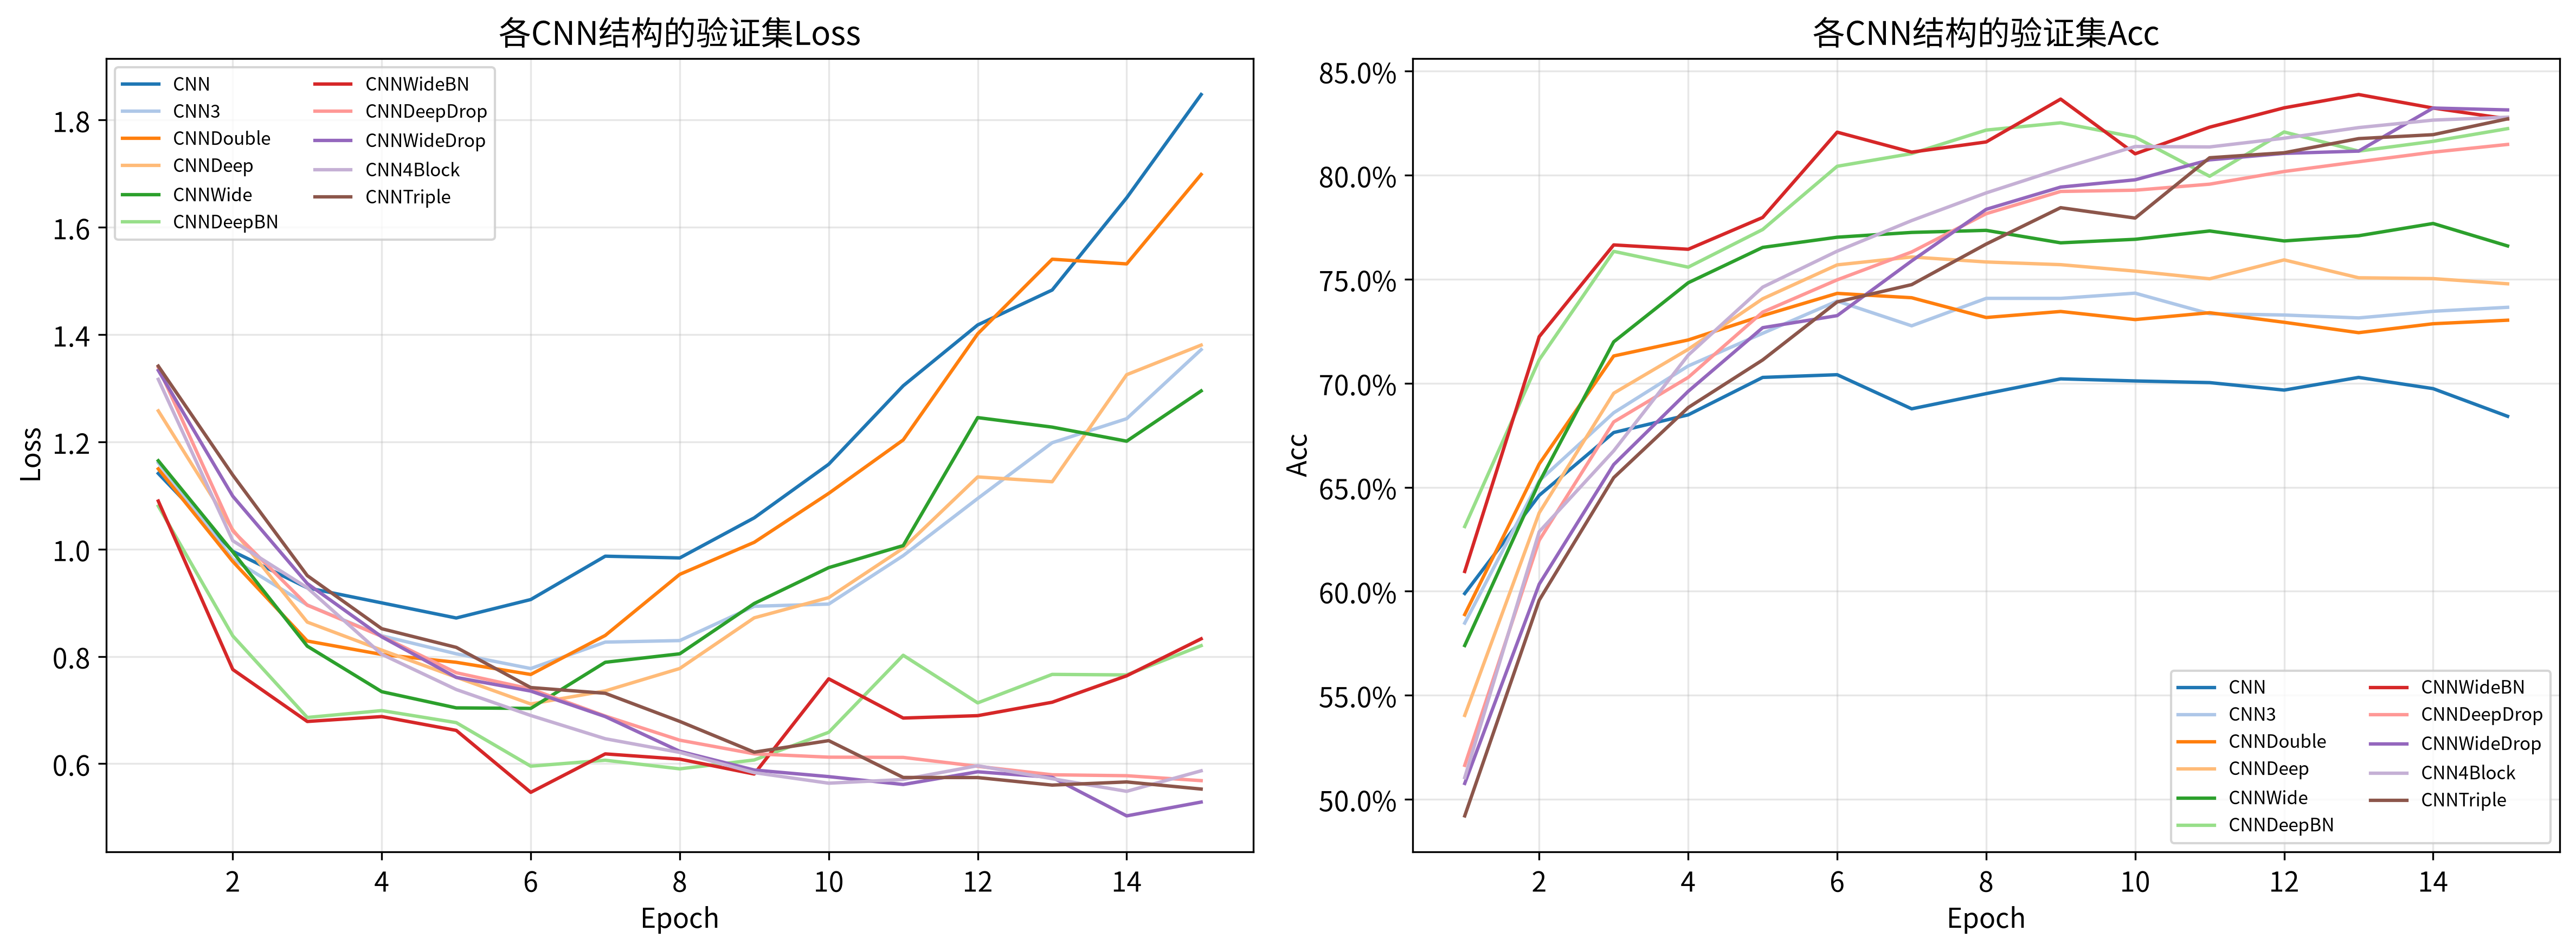

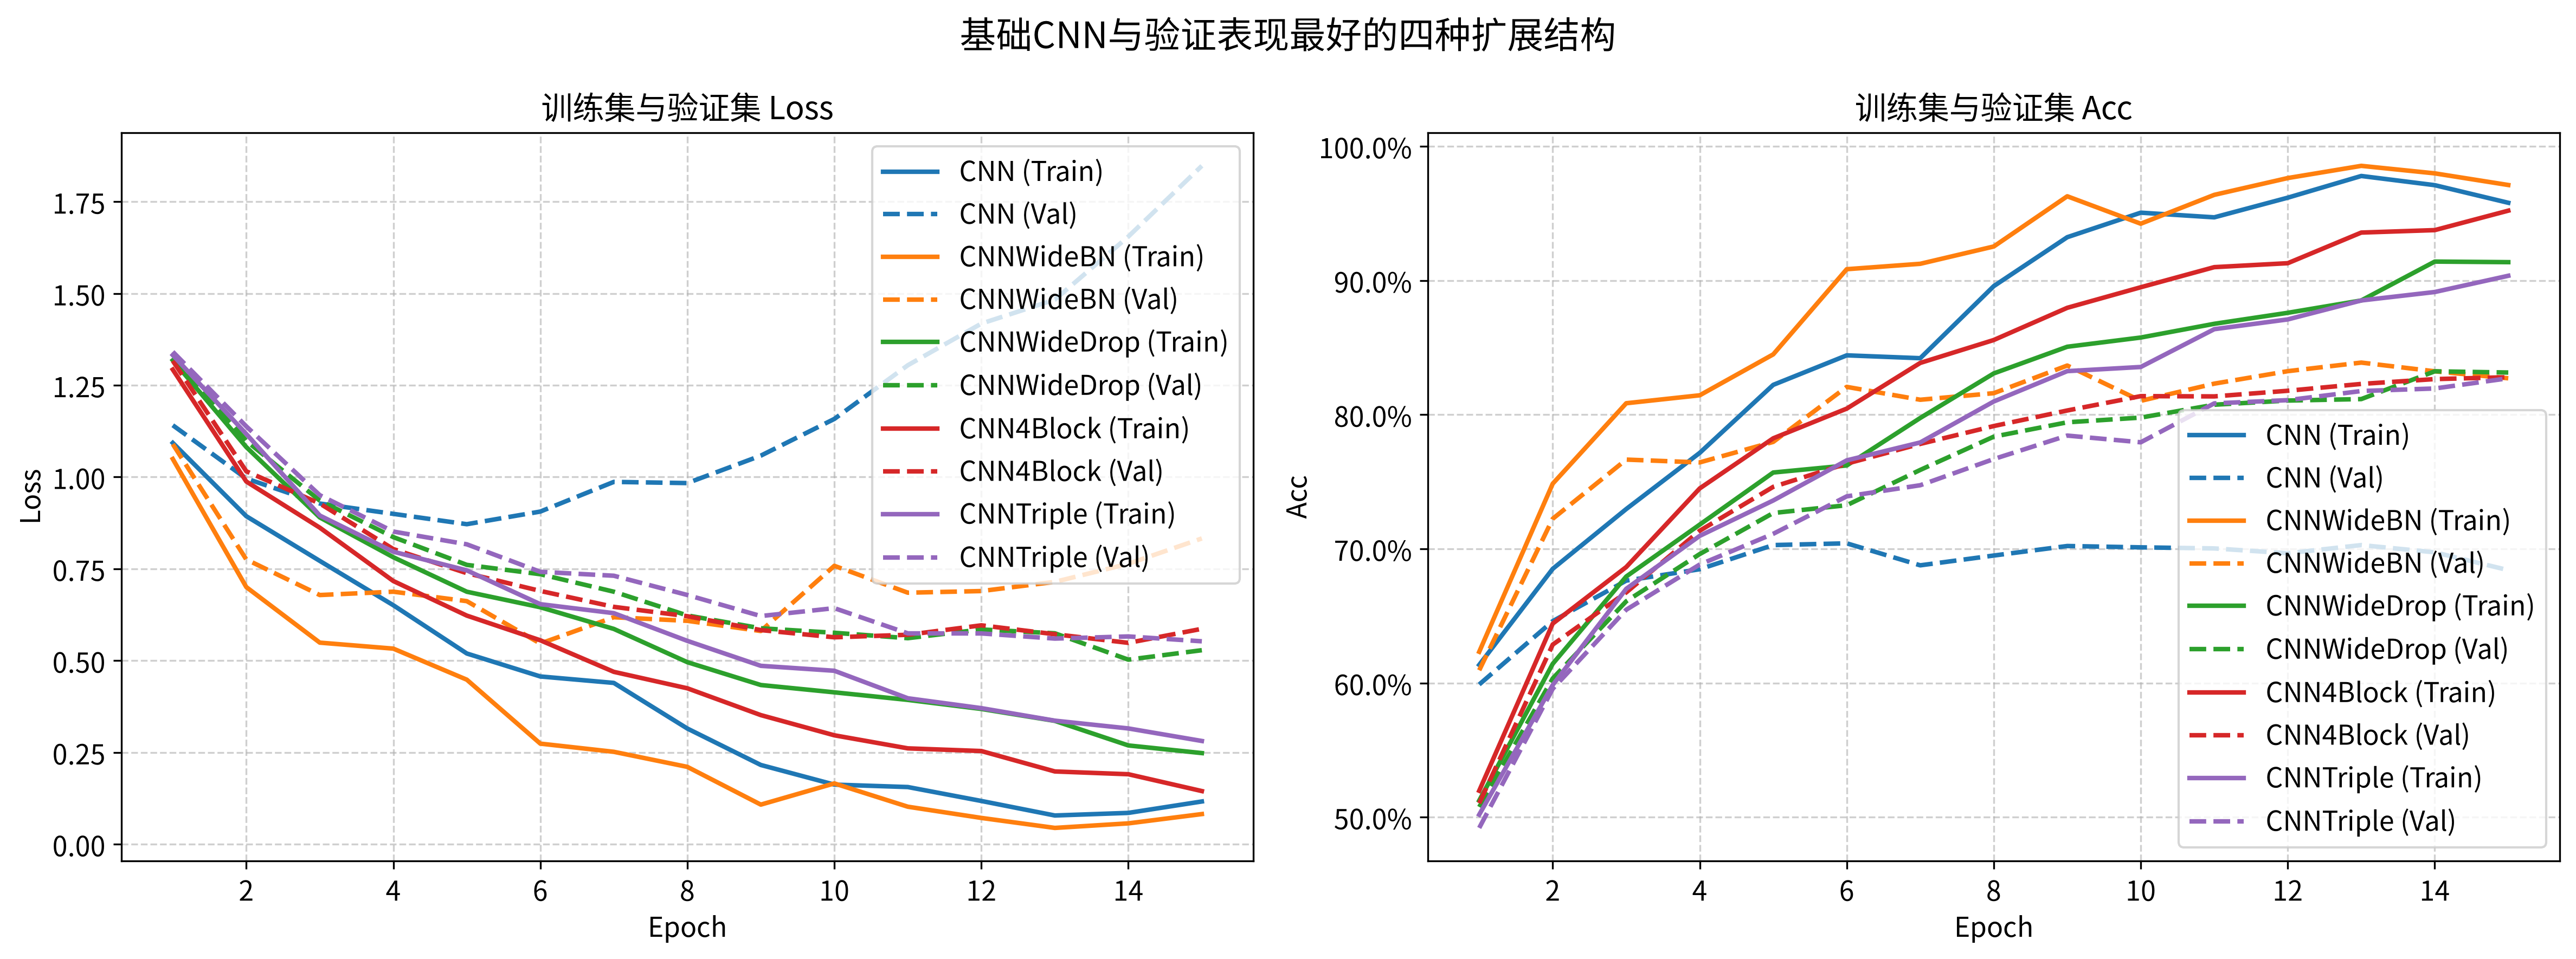

In [18]:
# 用不同颜色比较所有结构的验证表现，实测结果均来自固定验证集。
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = plt.get_cmap('tab20').colors
for i, (name, history) in enumerate(results_dict.items()):
    axes[0].plot(history['Epoch'], history['Val_Loss'], color=colors[i], label=name)
    axes[1].plot(history['Epoch'], history['Val_Acc'], color=colors[i], label=name)
for ax, metric in zip(axes, ['Loss', 'Acc']):
    ax.set_title(f'各CNN结构的验证集{metric}')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)
axes[1].yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'architecture_validation_curves.png', bbox_inches='tight')
plt.show()

# 依据验证集挑出四种扩展结构，画出它们与基础模型的训练／验证曲线。
ranked_names = sorted(
    [name for name in results_dict if name != 'CNN'],
    key=lambda name: (-results_dict[name]['Val_Acc'].max(),
                      results_dict[name].sort_values(['Val_Acc', 'Val_Loss'],
                                                    ascending=[False, True]).iloc[0]['Val_Loss']))
curve_names = ['CNN'] + ranked_names[:4]
plot_multiple_models_train_result({name: results_dict[name] for name in curve_names},
                                  '基础CNN与验证表现最好的四种扩展结构')


In [19]:
# 在固定测试集上计算模型指标，并保留10个类别的预测概率。
# 对固定测试集评估；该函数只在所有候选模型与最佳轮次确定后调用。
def evaluate_model(model, batch=128):
    model.eval()
    test_correct, test_num, test_total_loss_sum = 0, 0, 0.0
    test_result, test_probs = [], []
    # 测试阶段关闭梯度计算，并按原顺序收集每个样本的预测。
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            test_preds = model(batch_x)
            loss = criterion(test_preds, batch_y)
            # 累计Loss总和与预测正确数，最终除以完整测试集样本数。
            test_total_loss_sum += loss.item() * batch_y.size(0)
            predicted_classes = test_preds.argmax(dim=1) # 最大logit对应预测类别
            test_correct += (predicted_classes == batch_y).sum().item()
            test_num += batch_y.size(0)
            test_result += predicted_classes.cpu().tolist()
            test_probs += test_preds.softmax(dim=1).cpu().tolist() # 仅在展示概率时使用Softmax

    # 结果表保留预测标签与10列概率，attrs中保存整体测试指标。
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    prob_df = pd.DataFrame(test_probs, columns=[f'Prob_{i}' for i in range(10)])
    result_df = pd.concat([result_df, prob_df], axis=1)
    result_df.attrs['Loss'] = test_total_loss_sum / test_num
    result_df.attrs['Acc'] = test_correct / test_num
    print(f"测试集 Loss: {result_df.attrs['Loss']:.4f}，Acc: {result_df.attrs['Acc']:.2%}")
    return result_df


#### 三、验证集选模与独立测试
（1）先按最佳验证 Acc 排序（相同则比较验证 Loss），固定最终模型，再统一测试。
测试集不参与训练、最佳轮次选择或结构选择。参数量与训练时间同时列出，便于比较识别效果和计算代价。


In [20]:
# 只根据验证集结果选择最终结构，测试集不参与该选择。
validation_rows = []
for name, current_model in models.items():
    history = results_dict[name]
    # 读取训练时选中的最佳轮次，而不是直接使用最后一轮。
    best = history.iloc[current_model.best_epoch - 1]
    validation_rows.append({
        'Model': name, 'Parameters': sum(p.numel() for p in current_model.parameters()),
        'Best_Epoch': current_model.best_epoch,
        'Val_Loss': float(best['Val_Loss']), 'Val_Acc': float(best['Val_Acc']),
        'Seconds': current_model.training_seconds
    })
# 验证Acc越高越优；相同时选择验证Loss较小的结构。
validation_table = pd.DataFrame(validation_rows).sort_values(
    ['Val_Acc', 'Val_Loss'], ascending=[False, True]).reset_index(drop=True)
best_model_name = validation_table.iloc[0]['Model']
# 固定最终模型，后面的可视化和模型保存均使用它。
model = models[best_model_name]
print('按验证集选定的最终模型：', best_model_name)
display(validation_table.style.format({
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}', 'Seconds': '{:.1f}'
}).hide(axis='index'))


按验证集选定的最终模型： CNNWideBN


Model,Parameters,Best_Epoch,Val_Loss,Val_Acc,Seconds
CNNWideBN,1672906,13,0.7145,83.88%,41.9
CNNWideDrop,1672906,14,0.5026,83.23%,42.3
CNN4Block,1306666,15,0.5866,82.79%,37.5
CNNTriple,745674,15,0.5526,82.71%,39.0
CNNDeepBN,551466,9,0.6069,82.52%,32.8
CNNDeepDrop,551466,15,0.5683,81.48%,34.0
CNNWide,1671114,14,1.2013,77.68%,39.1
CNNDeep,550570,7,0.7357,76.07%,32.6
CNN3,356810,10,0.8975,74.33%,31.9
CNNDouble,591274,6,0.7663,74.32%,31.9


In [21]:
# 统一测试所有已完成验证比较的结构，保存每个模型的预测记录和比较表。
predictions, comparison_rows = {}, []
y_true = np.asarray(test_dataset.targets)
# 所有结构已按验证集定好权重，此处才开始读取测试指标。
for name, current_model in models.items():
    print('\n模型：', name)
    result = evaluate_model(current_model)
    predictions[name] = result
    result.to_csv(OUTPUT_DIR / f'{name}_test_predictions.csv', index=False)
    row = validation_table.loc[validation_table['Model'] == name].iloc[0].to_dict()
    comparison_rows.append({**row, 'Test_Loss': result.attrs['Loss'],
                            'Test_Acc': result.attrs['Acc']})
# 汇总验证与测试表现；逐样本预测另存CSV，便于检查误分类。
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
display(comparison_table.style.format({
    'Val_Loss': '{:.4f}', 'Val_Acc': '{:.2%}', 'Test_Loss': '{:.4f}',
    'Test_Acc': '{:.2%}', 'Seconds': '{:.1f}'
}).hide(axis='index'))
test_result = predictions[best_model_name]
display(test_result.head(10).round(4))



模型： CNN


测试集 Loss: 0.9033，Acc: 70.00%

模型： CNN3


测试集 Loss: 0.8936，Acc: 74.11%

模型： CNNDouble


测试集 Loss: 0.7674，Acc: 74.53%

模型： CNNDeep


测试集 Loss: 0.7597，Acc: 75.46%

模型： CNNWide


测试集 Loss: 1.2663，Acc: 76.63%

模型： CNNDeepBN


... (4 outputs left out)

测试集 Loss: 0.5856，Acc: 82.89%

模型： CNNTriple


测试集 Loss: 0.5501，Acc: 82.46%


Model,Parameters,Best_Epoch,Val_Loss,Val_Acc,Seconds,Test_Loss,Test_Acc
CNN,545098,6,0.9060,70.41%,32.5,0.9033,70.00%
CNN3,356810,10,0.8975,74.33%,31.9,0.8936,74.11%
CNNDouble,591274,6,0.7663,74.32%,31.9,0.7674,74.53%
CNNDeep,550570,7,0.7357,76.07%,32.6,0.7597,75.46%
CNNWide,1671114,14,1.2013,77.68%,39.1,1.2663,76.63%
CNNDeepBN,551466,9,0.6069,82.52%,32.8,0.6243,82.20%
CNNWideBN,1672906,13,0.7145,83.88%,41.9,0.7355,84.00%
CNNDeepDrop,551466,15,0.5683,81.48%,34.0,0.5703,81.77%
CNNWideDrop,1672906,14,0.5026,83.23%,42.3,0.5204,82.97%
CNN4Block,1306666,15,0.5866,82.79%,37.5,0.5856,82.89%


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,3,0.0000,0.0000,0.0000,0.9995,0.0000,0.0005,0.0000,0.0000,0.0000,0.0000
1,8,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
2,8,0.0029,0.1278,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8588,0.0104
3,0,0.5800,0.0472,0.0967,0.0305,0.0004,0.0001,0.0000,0.0000,0.2359,0.0093
4,6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000
5,6,0.0000,0.0000,0.0000,0.0001,0.0000,0.0018,0.9981,0.0000,0.0000,0.0000
6,9,0.0000,0.1148,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8852
7,6,0.0000,0.0000,0.0304,0.0005,0.3797,0.0001,0.5878,0.0016,0.0000,0.0000
8,3,0.0000,0.0000,0.0000,0.9979,0.0010,0.0000,0.0011,0.0000,0.0000,0.0000
9,1,0.0000,0.8097,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0002,0.1901


（2）查看最终模型的类别表现、混淆矩阵与部分识别结果。
对角线以外的位置表示误分类；分类报告可观察整体 Acc 是否掩盖某些类别的识别困难。


              precision    recall  f1-score   support

    airplane     0.8839    0.8070    0.8437      1000
  automobile     0.9544    0.9000    0.9264      1000
        bird     0.7398    0.7990    0.7683      1000
         cat     0.7438    0.6910    0.7164      1000
        deer     0.7910    0.8630    0.8254      1000
         dog     0.8517    0.7180    0.7792      1000
        frog     0.8141    0.9110    0.8598      1000
       horse     0.8456    0.8930    0.8687      1000
        ship     0.9159    0.9040    0.9099      1000
       truck     0.8797    0.9140    0.8965      1000

    accuracy                         0.8400     10000
   macro avg     0.8420    0.8400    0.8394     10000
weighted avg     0.8420    0.8400    0.8394     10000



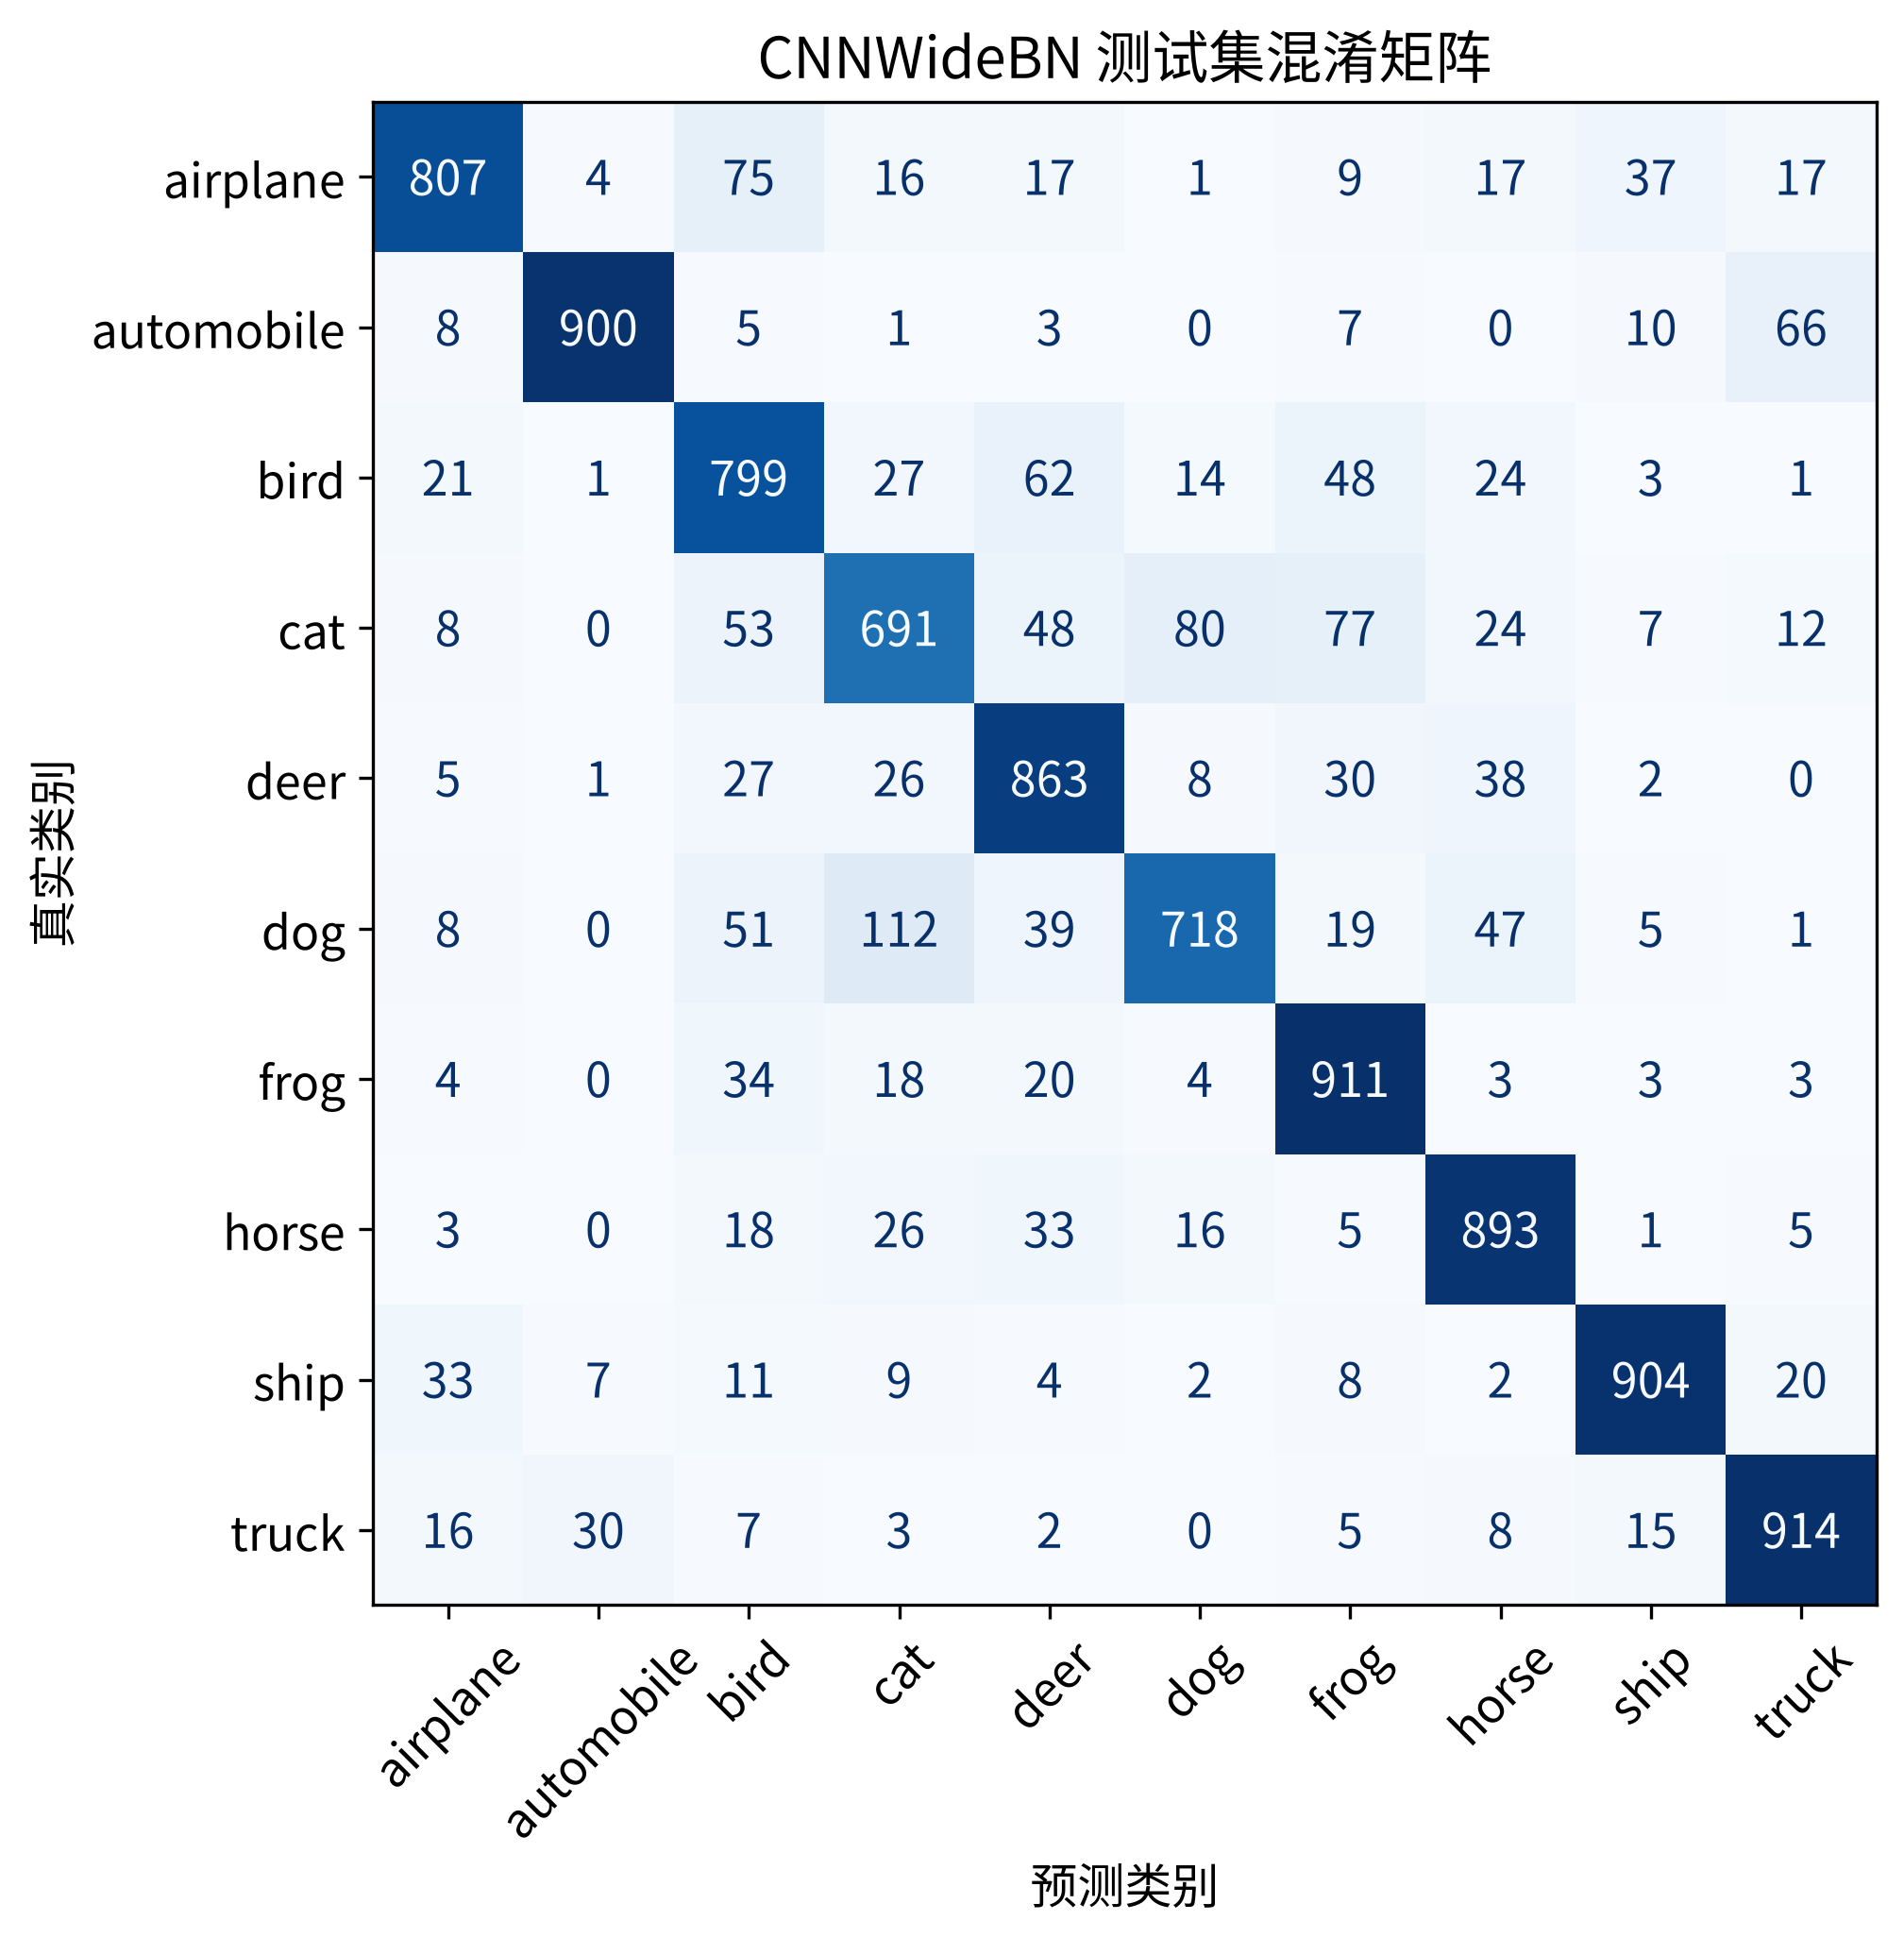

In [22]:
# 按CIFAR-10的类别顺序显示分类报告和混淆矩阵。
class_names = test_dataset.classes
# 分类报告分别给出各类别的Precision、Recall和F1。
print(classification_report(y_true, test_result['Predict'], labels=list(range(10)),
                            target_names=class_names, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 7))
# 混淆矩阵的行是真实类别，列是预测类别，非对角线表示错误。
ConfusionMatrixDisplay.from_predictions(
    y_true, test_result['Predict'], labels=list(range(10)),
    display_labels=class_names, cmap='Blues', ax=ax, colorbar=False,
    xticks_rotation=45
)
ax.set_title(f'{best_model_name} 测试集混淆矩阵')
ax.set_xlabel('预测类别')
ax.set_ylabel('真实类别')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrix.png', bbox_inches='tight')
plt.show()


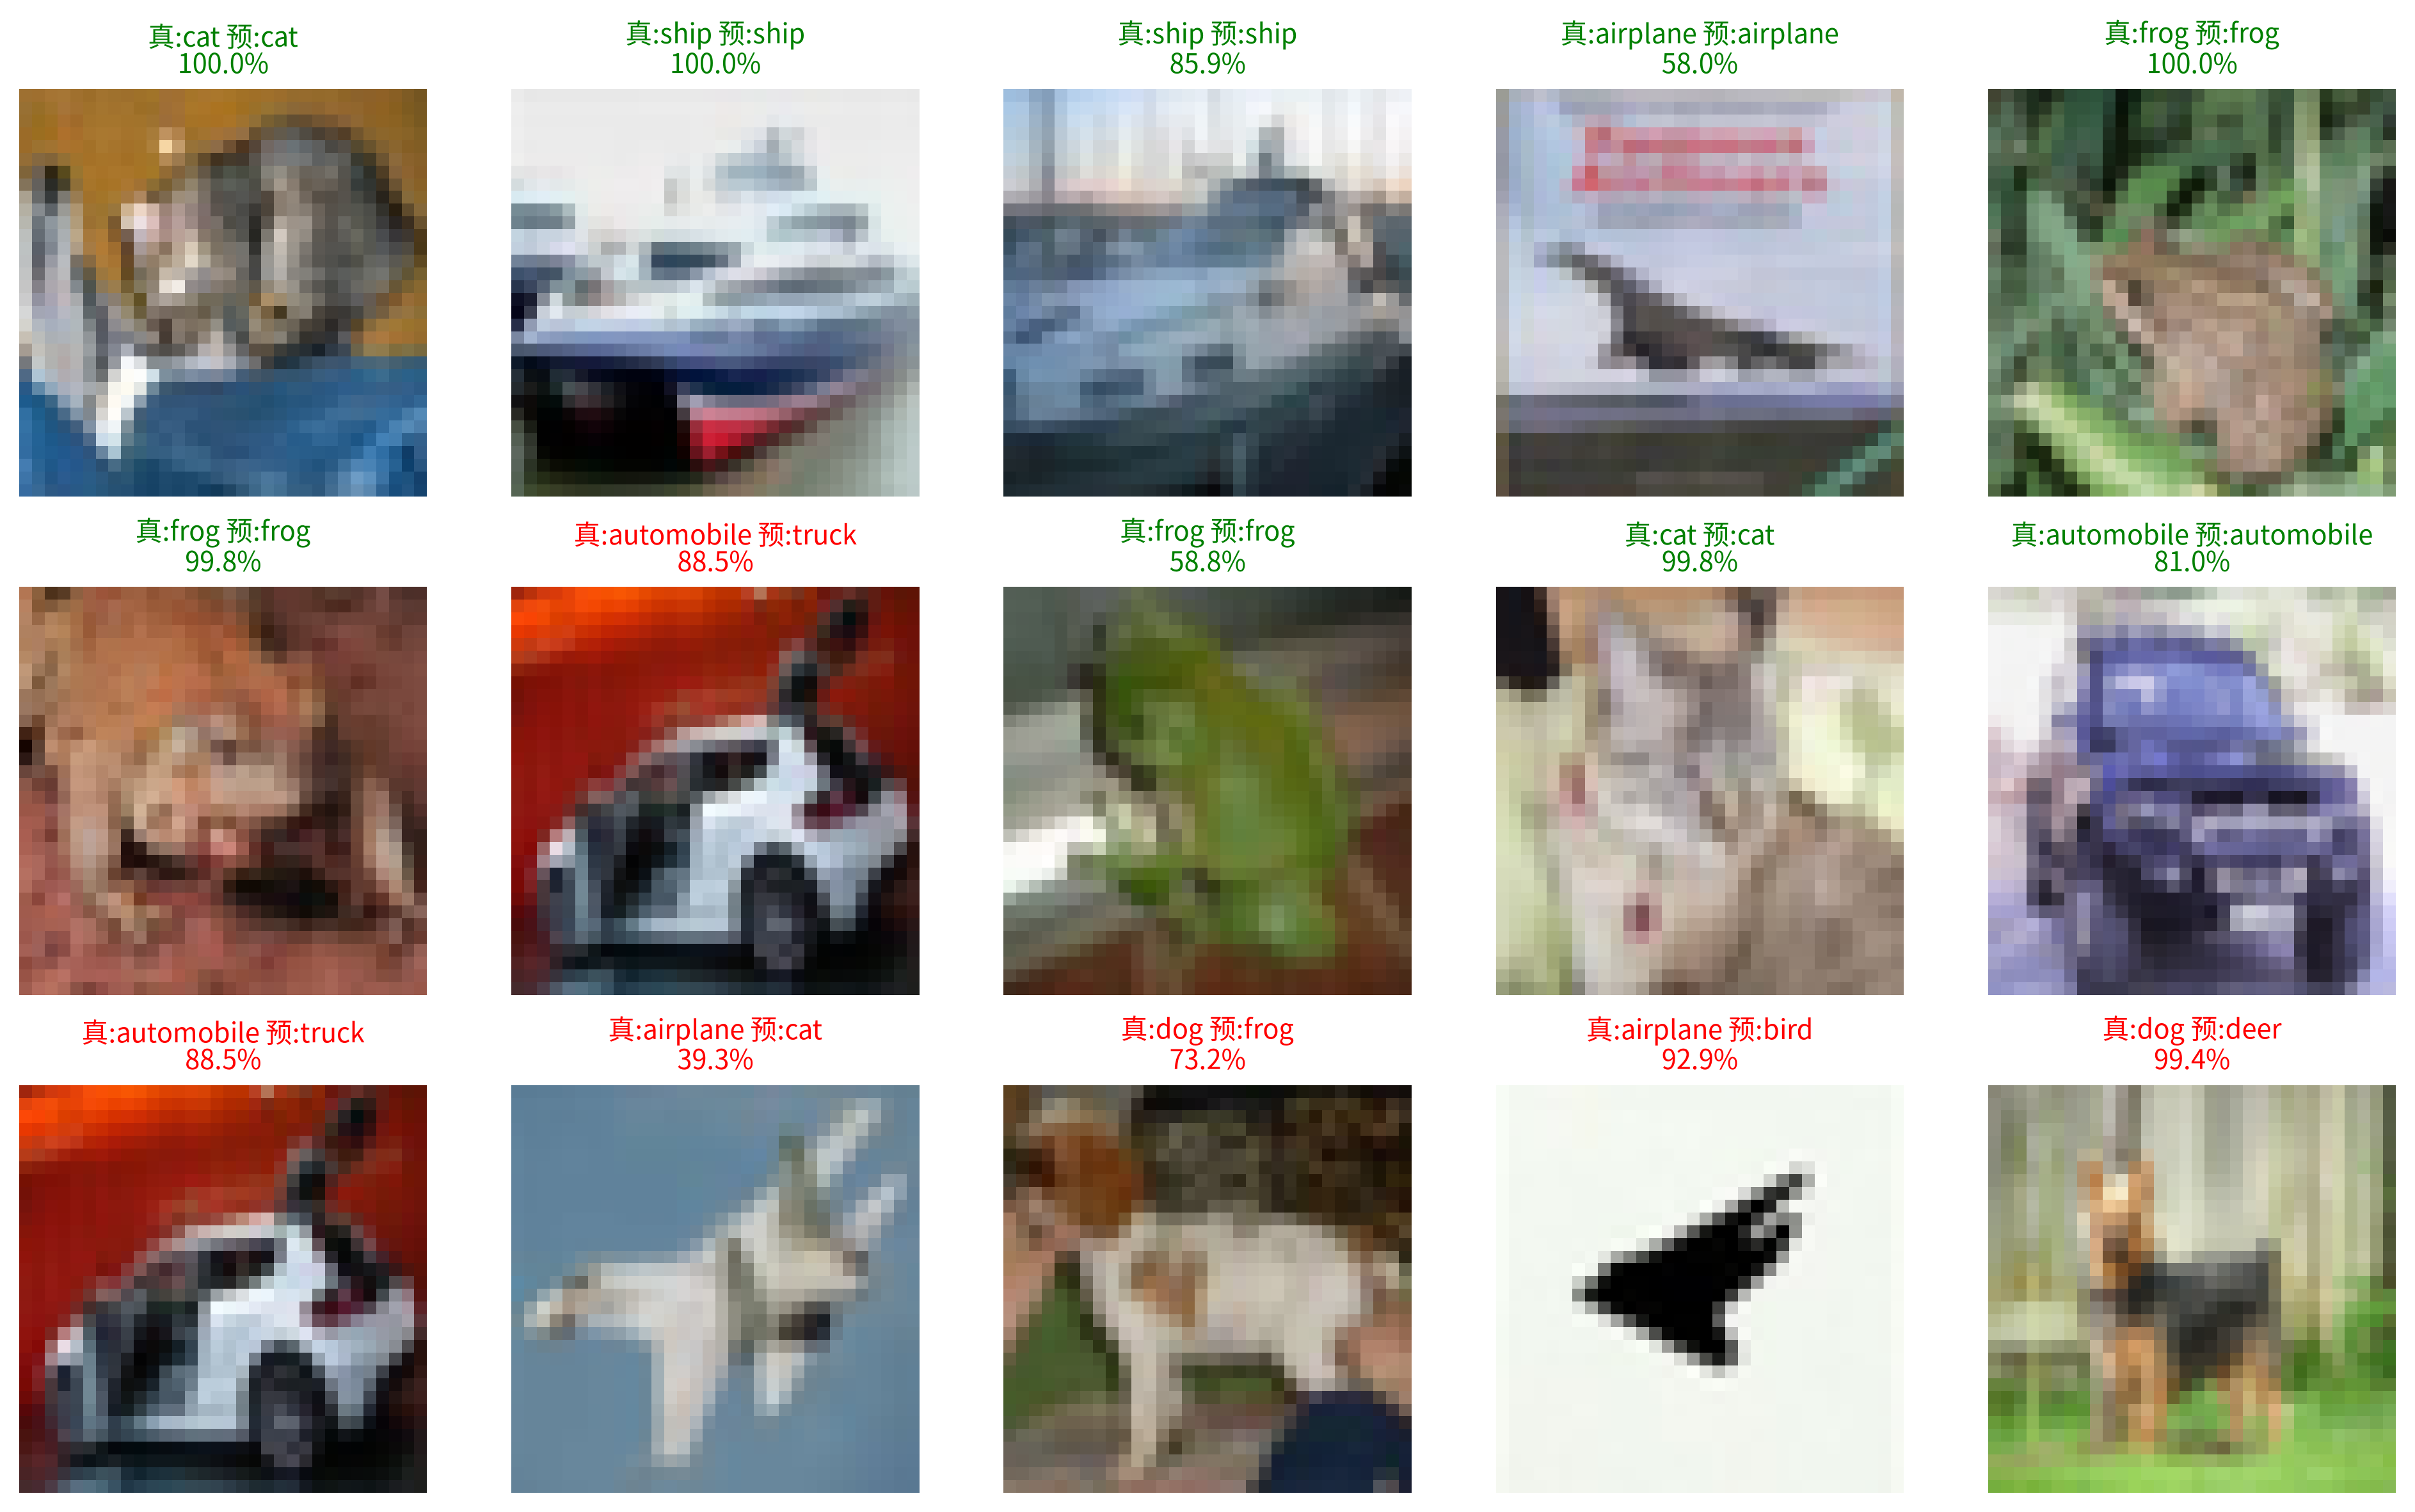

In [23]:
# 展示原始RGB测试图像，查看正确识别与误分类的具体样本。
# 前十张图与最多五张误分类样本，均来自独立测试集。
wrong = np.flatnonzero(test_result['Predict'].to_numpy() != y_true)
# 前十张图用于普通预测展示，另取最多五张误分类样本观察错误。
sample_indices = np.concatenate([np.arange(10), wrong[:5]])
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for ax in axes.flat:
    ax.axis('off')
for ax, index in zip(axes.flat, sample_indices):
    predicted = int(test_result.iloc[index]['Predict'])
    confidence = float(test_result.iloc[index][f'Prob_{predicted}']) # 预测类别的Softmax概率
    ax.imshow(test_dataset.data[index])
    # 绿色表示预测正确，红色表示误分类；高概率也可能出错。
    ax.set_title(f'真:{class_names[int(y_true[index])]} 预:{class_names[predicted]}\n{confidence:.1%}',
                 color='green' if predicted == y_true[index] else 'red', fontsize=10)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'prediction_examples.png', bbox_inches='tight')
plt.show()


（3）保存验证集选中的最终模型，并重新加载检查预测是否一致。
权重、结构名称、输入形状、预处理方式和类别顺序一并保存，后续真实图片必须使用同样的预处理。


In [24]:
# 保存最终模型的权重、结构与图像预处理配置，并检查加载结果。
experiment_config = {
    'dataset': 'CIFAR-10', 'split_sizes': [len(train_dataset), len(val_dataset), len(test_dataset)],
    'input_shape': [3, 32, 32], 'normalization': {'mean': [0.5] * 3, 'std': [0.5] * 3},
    'optimizer': 'Adam', 'learning_rate': 0.001, 'epochs': 15, 'batch': 64,
    'seed': 42, 'validation_ratio': 0.2, 'classes': class_names,
    'architecture': next((config for config in architecture_configs
                          if config['name'] == best_model_name), None),
    'augmentation': False,
    'best_model': best_model_name, 'best_epoch': int(model.best_epoch),
    'selection': 'maximum validation accuracy; minimum validation loss for ties'
}
# 同时保存state_dict和输入配置，便于使用相同结构和预处理恢复模型。
torch.save({'model_state_dict': model.state_dict(), 'config': experiment_config},
           OUTPUT_DIR / 'best_model.pt')
# 从刚保存的文件重建模型，再在同一批输入上比较输出。
checkpoint = torch.load(OUTPUT_DIR / 'best_model.pt', map_location=device, weights_only=True)
reloaded = model_classes[checkpoint['config']['best_model']]().to(device)
reloaded.load_state_dict(checkpoint['model_state_dict'])
reloaded.eval()
with torch.no_grad():
    sample_x = next(iter(test_loader))[0][:32].to(device)
    # 加载前后logits应在浮点容差内一致，否则说明恢复过程有误。
    assert torch.allclose(model(sample_x), reloaded(sample_x), atol=1e-6)
# 保存实验配置和比较结果，作为本次实测记录。
summary = {'config': experiment_config, 'comparison': comparison_table.to_dict(orient='records')}
(OUTPUT_DIR / 'summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('已保存并验证最佳模型：', OUTPUT_DIR / 'best_model.pt')


已保存并验证最佳模型： outputs/best_model.pt


#### 四、实验结果与性能分析

##### 4.1 统一条件下的实测结果

本轮在原有三种结构上新增八种基础CNN变体，共比较11种结构。均使用40000张训练图像、10000张固定验证图像和10000张独立测试图像；Adam学习率0.001，batch=64，训练15轮，随机种子42。预处理仍为ToTensor和Normalize(0.5, 0.5)，未新增数据增强。

| 模型 | 参数量 | 最佳轮次 | 训练Acc | 验证Acc | 测试Acc |
| :--- | ---: | ---: | ---: | ---: | ---: |
| CNN | 545,098 | 6 | 84.42% | 70.41% | 70.00% |
| CNN3 | 356,810 | 10 | 93.45% | 74.33% | 74.11% |
| CNNDouble | 591,274 | 6 | 88.22% | 74.32% | 74.53% |
| CNNDeep | 550,570 | 7 | 89.88% | 76.07% | 75.46% |
| CNNWide | 1,671,114 | 14 | 97.23% | 77.68% | 76.63% |
| CNNDeepBN | 551,466 | 9 | 96.21% | 82.52% | 82.20% |
| CNNWideBN | 1,672,906 | 13 | 98.54% | 83.88% | 84.00% |
| CNNDeepDrop | 551,466 | 15 | 90.64% | 81.48% | 81.77% |
| CNNWideDrop | 1,672,906 | 14 | 91.41% | 83.23% | 82.97% |
| CNN4Block | 1,306,666 | 15 | 95.20% | 82.79% | 82.89% |
| CNNTriple | 745,674 | 15 | 90.35% | 82.71% | 82.46% |

按验证集选出的最终模型为 **CNNWideBN**，最佳第 **13轮**，验证Acc **83.88%**，独立测试Acc **84.00%**。相较前次验证集选中的CNN3，验证Acc提高 **9.55个百分点**，测试Acc提高 **9.89个百分点**。

##### 4.2 不同结构改动的作用

（1）增加卷积层和通道数：三块、每块两层卷积的CNNDeep验证Acc为76.07%，加宽到64→128→256后，CNNWide达到77.68%。单纯增加容量有一定帮助，但CNNWide训练Acc已达97.23%，与验证集仍有19.55个百分点的差距，过拟合比较明显。

（2）在卷积后加入BatchNorm：相同窄结构从76.07%提高到82.52%，相同宽结构从77.68%提高到83.88%，分别提高6.45和6.20个百分点。在本轮固定训练条件下，BatchNorm是收益最明显的结构改动；它对中间特征进行归一化，有助于较深CNN在当前学习率下稳定训练。

（3）加入Dropout：CNNWideDrop验证Acc为83.23%，训练Acc为91.41%，训练与验证差距缩小为8.18个百分点，但验证Acc略低于CNNWideBN。CNNDeepDrop也没有超过对应的无Dropout版本。这说明当前15轮设置下，Dropout减轻了拟合程度，同时可能需要更长的训练才能充分收敛；不能仅因本次未胜出就认定Dropout无效。

（4）继续增加深度：四块结构CNN4Block和每块三层卷积的CNNTriple分别达到82.79%和82.71%。它们都超过80%，但未超过三块、每块两层卷积的宽结构。当前结果说明，更深或更多池化并不必然带来更高准确率。
